In [21]:

# Explicitly initialize CUDA contexts before GAN training
import torch

if torch.cuda.is_available():
    for gpu_id in range(torch.cuda.device_count()):
        torch.cuda.set_device(gpu_id)
        _ = torch.empty(1, device=f"cuda:{gpu_id}")
    torch.cuda.synchronize()

print("CUDA initialized on all available GPUs.")


CUDA initialized on all available GPUs.


PyTorch: 2.11.0+cu128
Device: cuda
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

Training split: 4243 images
Batch shape: (32, 1, 224, 224)
Pixel range: (-1.0, 1.0)

Generator parameters: 2,340,320
Discriminator parameters: 739,745
Generated batch shape: (4, 1, 224, 224)
Real logits shape: (4,)
Fake logits shape: (4,)


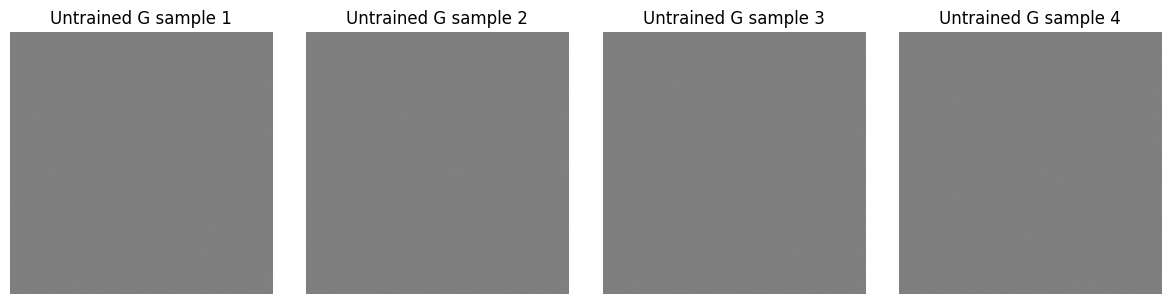


SETUP AND SMOKE TEST PASSED.
Output directory: /kaggle/working/ubiris_v2_project/notebook07_gan_augmentation
Note: the preview is from an untrained generator.


In [25]:

# ============================================================
# NOTEBOOK 07 — UBIRIS V2 GAN AUGMENTATION
# Setup + dataset verification + DCGAN architecture + smoke test
# ============================================================

from pathlib import Path
import time, random, json
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from tqdm.auto import tqdm

# -------------------- 1. Reproducibility --------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# -------------------- 2. Paths and environment --------------
PROJECT = Path("/kaggle/working/ubiris_v2_project")
PRE_DIR = PROJECT / "notebook02_preprocessing"
BASELINE_DIR = PROJECT / "notebook04_baseline_recognition"
OUT_DIR = PROJECT / "notebook07_gan_augmentation"
SAMPLE_DIR = OUT_DIR / "samples"
OUT_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

IMG_DIR = PRE_DIR / "images_224"
TRAIN_CSV = BASELINE_DIR / "UBIRIS_V2_train_split.csv"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

assert IMG_DIR.is_dir(), f"Missing images: {IMG_DIR}"
assert TRAIN_CSV.is_file(), f"Missing training split: {TRAIN_CSV}"

train_df = pd.read_csv(TRAIN_CSV)
assert len(train_df) > 0
print("\nTraining split:", len(train_df), "images")

# -------------------- 3. Dataset -----------------------------
class UBIRISDataset(Dataset):
    def __init__(self, df, image_dir):
        self.df = df.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transforms.Compose([
            transforms.Grayscale(num_output_channels=1),
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize((0.5,), (0.5,))
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        filename = Path(str(self.df.iloc[idx]["filename"])).stem + ".png"
        path = self.image_dir / filename
        with Image.open(path) as im:
            return self.transform(im.convert("L"))

BATCH_SIZE = 32
NUM_WORKERS = 2

dataset = UBIRISDataset(train_df, IMG_DIR)
loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    drop_last=True
)

real_batch = next(iter(loader))
print("Batch shape:", tuple(real_batch.shape))
print("Pixel range:", (real_batch.min().item(), real_batch.max().item()))
assert real_batch.shape == (BATCH_SIZE, 1, 224, 224)

# -------------------- 4. Compact DCGAN -----------------------
# Generator: latent vector -> 224x224 grayscale image.
# Discriminator: image -> real/fake logit.
LATENT_DIM = 128
FEATURES_G = 32
FEATURES_D = 32

class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, features=FEATURES_G):
        super().__init__()
        self.project = nn.Sequential(
            nn.Linear(latent_dim, features * 8 * 7 * 7),
            nn.BatchNorm1d(features * 8 * 7 * 7),
            nn.ReLU(True)
        )
        self.net = nn.Sequential(
            # 7 -> 14
            nn.ConvTranspose2d(features * 8, features * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features * 4), nn.ReLU(True),
            # 14 -> 28
            nn.ConvTranspose2d(features * 4, features * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features * 2), nn.ReLU(True),
            # 28 -> 56
            nn.ConvTranspose2d(features * 2, features, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features), nn.ReLU(True),
            # 56 -> 112
            nn.ConvTranspose2d(features, features // 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features // 2), nn.ReLU(True),
            # 112 -> 224
            nn.ConvTranspose2d(features // 2, 1, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        x = self.project(z)
        x = x.view(z.size(0), FEATURES_G * 8, 7, 7)
        return self.net(x)

class Discriminator(nn.Module):
    def __init__(self, features=FEATURES_D):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, features, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),
            # 224 -> 112
            nn.Conv2d(features, features * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features * 2), nn.LeakyReLU(0.2, inplace=True),
            # 112 -> 56
            nn.Conv2d(features * 2, features * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features * 4), nn.LeakyReLU(0.2, inplace=True),
            # 56 -> 28
            nn.Conv2d(features * 4, features * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features * 8), nn.LeakyReLU(0.2, inplace=True),
            # 28 -> 14
            nn.Conv2d(features * 8, 1, 14, 1, 0)
        )

    def forward(self, x):
        return self.net(x).view(-1)

def init_weights(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d, nn.BatchNorm2d)):
        if getattr(module, "weight", None) is not None:
            nn.init.normal_(module.weight.data, 0.0, 0.02)
        if getattr(module, "bias", None) is not None:
            nn.init.zeros_(module.bias.data)

G = Generator().to(device)
D = Discriminator().to(device)
G.apply(init_weights)
D.apply(init_weights)

# Explicitly use both GPUs if available.
if torch.cuda.device_count() > 1:
    G = nn.DataParallel(G)
    D = nn.DataParallel(D)

print("\nGenerator parameters:",
      f"{sum(p.numel() for p in G.parameters()):,}")
print("Discriminator parameters:",
      f"{sum(p.numel() for p in D.parameters()):,}")

# -------------------- 5. Forward-pass smoke test -------------
z = torch.randn(4, LATENT_DIM, device=device)
with torch.no_grad():
    fake_batch = G(z)
    real_logits = D(real_batch[:4].to(device))
    fake_logits = D(fake_batch)

print("Generated batch shape:", tuple(fake_batch.shape))
print("Real logits shape:", tuple(real_logits.shape))
print("Fake logits shape:", tuple(fake_logits.shape))
assert fake_batch.shape == (4, 1, 224, 224)
assert real_logits.shape == (4,)
assert fake_logits.shape == (4,)
assert torch.isfinite(fake_batch).all()

# Save a randomly initialized generator preview for pipeline verification.
# These are NOT trained GAN samples.
preview = (fake_batch.detach().cpu() + 1) / 2
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i, ax in enumerate(axes):
    ax.imshow(preview[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Untrained G sample {i+1}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUT_DIR / "UBIRIS_V2_GAN_untrained_preview.png", dpi=130)
plt.show()
plt.close(fig)

print("\nSETUP AND SMOKE TEST PASSED.")
print("Output directory:", OUT_DIR)
print("Note: the preview is from an untrained generator.")


In [24]:

import torch
import torch.nn as nn

# Clear cached GPU memory where possible.
if torch.cuda.is_available():
    torch.cuda.set_device(0)
    torch.cuda.empty_cache()

# Unwrap if the models are already wrapped in DataParallel.
if isinstance(G, nn.DataParallel):
    G = G.module
if isinstance(D, nn.DataParallel):
    D = D.module

# Move the underlying models to the primary GPU BEFORE wrapping.
G = G.to(device="cuda:0")
D = D.to(device="cuda:0")

# Wrap both models for multi-GPU execution.
if torch.cuda.device_count() > 1:
    G = nn.DataParallel(G, device_ids=[0, 1], output_device=0)
    D = nn.DataParallel(D, device_ids=[0, 1], output_device=0)

# Verify parameter placement.
print("Generator primary device:", next(G.parameters()).device)
print("Discriminator primary device:", next(D.parameters()).device)

# Test the generator and discriminator again.
G.eval()
D.eval()

with torch.no_grad():
    z = torch.randn(8, LATENT_DIM, device="cuda:0")
    fake = G(z)
    logits = D(fake)

print("Generated shape:", tuple(fake.shape))
print("Discriminator output shape:", tuple(logits.shape))

assert fake.shape == (8, 1, 224, 224)
assert logits.shape == (8,)
assert torch.isfinite(fake).all()

G.train()
D.train()

print("\nGPU placement fixed. GAN smoke test passed.")


Generator primary device: cuda:0
Discriminator primary device: cuda:0
Generated shape: (8, 1, 224, 224)
Discriminator output shape: (8,)

GPU placement fixed. GAN smoke test passed.


Starting GAN training
Epochs: 5
Training images: 4243
Batch size: 32
GPUs: 2


GAN Epoch 1/5:   0%|          | 0/132 [00:00<?, ?it/s]

Epoch 1: D_loss=0.07038, G_loss=4.48642, time=0.21 min


GAN Epoch 2/5:   0%|          | 0/132 [00:00<?, ?it/s]

Epoch 2: D_loss=0.06265, G_loss=6.39528, time=0.37 min


...

Epoch 3: D_loss=0.22121, G_loss=3.71984, time=0.20 min


GAN Epoch 4/5:   0%|          | 0/132 [00:00<?, ?it/s]

Epoch 4: D_loss=0.34268, G_loss=2.75801, time=0.20 min


GAN Epoch 5/5:   0%|          | 0/132 [00:00<?, ?it/s]

Epoch 5: D_loss=0.39968, G_loss=2.14443, time=0.20 min

GAN TRAINING COMPLETE
Total duration: 1.19 min
Checkpoint: /kaggle/working/ubiris_v2_project/notebook07_gan_augmentation/UBIRIS_V2_GAN_checkpoint.pth
History: /kaggle/working/ubiris_v2_project/notebook07_gan_augmentation/UBIRIS_V2_GAN_training_history.csv
Sample previews: /kaggle/working/ubiris_v2_project/notebook07_gan_augmentation/samples


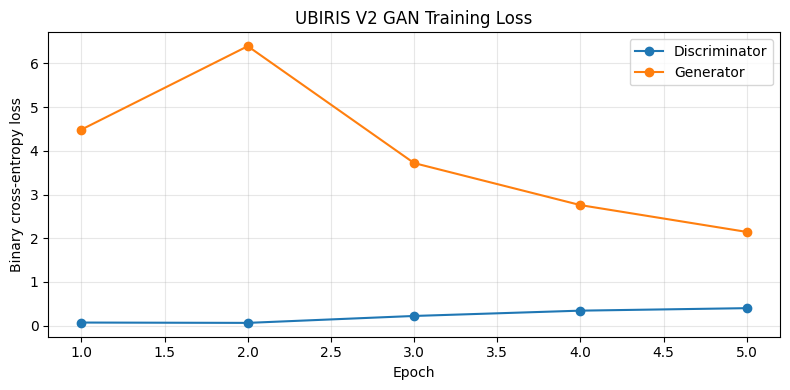

In [26]:

# ============================================================
# NOTEBOOK 07 — GAN TRAINING + CHECKPOINTS + SAMPLE PREVIEWS
# Requires: G, D, loader, device, LATENT_DIM, OUT_DIR
# ============================================================

import csv
import time
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from pathlib import Path
from torchvision.utils import save_image
from tqdm.auto import tqdm

OUT_DIR = Path("/kaggle/working/ubiris_v2_project/notebook07_gan_augmentation")
SAMPLE_DIR = OUT_DIR / "samples"
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 5
LR = 2e-4
BETA1 = 0.5
BETA2 = 0.999

# Keep a fixed noise batch so previews can be compared across epochs.
fixed_noise = torch.randn(8, LATENT_DIM, device="cuda:0")

criterion = nn.BCEWithLogitsLoss()
optimizer_G = optim.Adam(G.parameters(), lr=LR, betas=(BETA1, BETA2))
optimizer_D = optim.Adam(D.parameters(), lr=LR, betas=(BETA1, BETA2))

HISTORY_PATH = OUT_DIR / "UBIRIS_V2_GAN_training_history.csv"
CHECKPOINT_PATH = OUT_DIR / "UBIRIS_V2_GAN_checkpoint.pth"
history = []

print("Starting GAN training")
print("Epochs:", EPOCHS)
print("Training images:", len(loader.dataset))
print("Batch size:", loader.batch_size)
print("GPUs:", torch.cuda.device_count())

training_start = time.time()

for epoch in range(1, EPOCHS + 1):
    G.train()
    D.train()

    loss_G_total = 0.0
    loss_D_total = 0.0
    batches_seen = 0
    epoch_start = time.time()

    progress = tqdm(loader, desc=f"GAN Epoch {epoch}/{EPOCHS}")

    for real_images in progress:
        real_images = real_images.to("cuda:0", non_blocking=True)
        batch_size = real_images.size(0)

        real_targets = torch.ones(batch_size, device="cuda:0")
        fake_targets = torch.zeros(batch_size, device="cuda:0")

        # ---------------- Train discriminator ----------------
        optimizer_D.zero_grad(set_to_none=True)

        z = torch.randn(batch_size, LATENT_DIM, device="cuda:0")
        fake_images = G(z)

        real_logits = D(real_images)
        fake_logits = D(fake_images.detach())

        loss_D_real = criterion(real_logits, real_targets)
        loss_D_fake = criterion(fake_logits, fake_targets)
        loss_D = (loss_D_real + loss_D_fake) / 2

        loss_D.backward()
        optimizer_D.step()

        # ---------------- Train generator --------------------
        optimizer_G.zero_grad(set_to_none=True)

        z = torch.randn(batch_size, LATENT_DIM, device="cuda:0")
        generated_images = G(z)
        generated_logits = D(generated_images)

        loss_G = criterion(generated_logits, real_targets)
        loss_G.backward()
        optimizer_G.step()

        loss_D_total += loss_D.item()
        loss_G_total += loss_G.item()
        batches_seen += 1

        progress.set_postfix(
            D=f"{loss_D.item():.3f}",
            G=f"{loss_G.item():.3f}"
        )

    mean_D = loss_D_total / batches_seen
    mean_G = loss_G_total / batches_seen
    epoch_seconds = time.time() - epoch_start

    record = {
        "epoch": epoch,
        "discriminator_loss": mean_D,
        "generator_loss": mean_G,
        "batches": batches_seen,
        "epoch_seconds": round(epoch_seconds, 2),
        "learning_rate": LR
    }
    history.append(record)

    with open(HISTORY_PATH, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=record.keys())
        writer.writeheader()
        writer.writerows(history)

    # Save checkpoint after every epoch.
    g_state = G.module.state_dict() if isinstance(G, nn.DataParallel) else G.state_dict()
    d_state = D.module.state_dict() if isinstance(D, nn.DataParallel) else D.state_dict()

    torch.save({
        "epoch": epoch,
        "generator_state_dict": g_state,
        "discriminator_state_dict": d_state,
        "optimizer_G_state_dict": optimizer_G.state_dict(),
        "optimizer_D_state_dict": optimizer_D.state_dict(),
        "generator_loss": mean_G,
        "discriminator_loss": mean_D,
        "latent_dim": LATENT_DIM
    }, CHECKPOINT_PATH)

    # Save a consistent sample grid after each epoch.
    G.eval()
    with torch.no_grad():
        preview = G(fixed_noise).detach().cpu()
        preview = (preview + 1) / 2
        preview = preview.clamp(0, 1)

        sample_path = SAMPLE_DIR / f"UBIRIS_V2_GAN_epoch_{epoch:02d}.png"
        save_image(preview, sample_path, nrow=4)

    print(
        f"Epoch {epoch}: D_loss={mean_D:.5f}, "
        f"G_loss={mean_G:.5f}, time={epoch_seconds / 60:.2f} min"
    )

print("\nGAN TRAINING COMPLETE")
print(f"Total duration: {(time.time() - training_start) / 60:.2f} min")
print("Checkpoint:", CHECKPOINT_PATH)
print("History:", HISTORY_PATH)
print("Sample previews:", SAMPLE_DIR)

# Plot both losses.
hist_df = __import__("pandas").DataFrame(history)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist_df["epoch"], hist_df["discriminator_loss"], marker="o", label="Discriminator")
ax.plot(hist_df["epoch"], hist_df["generator_loss"], marker="o", label="Generator")
ax.set_xlabel("Epoch")
ax.set_ylabel("Binary cross-entropy loss")
ax.set_title("UBIRIS V2 GAN Training Loss")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "UBIRIS_V2_GAN_loss_curve.png", dpi=140)
plt.show()
plt.close(fig)


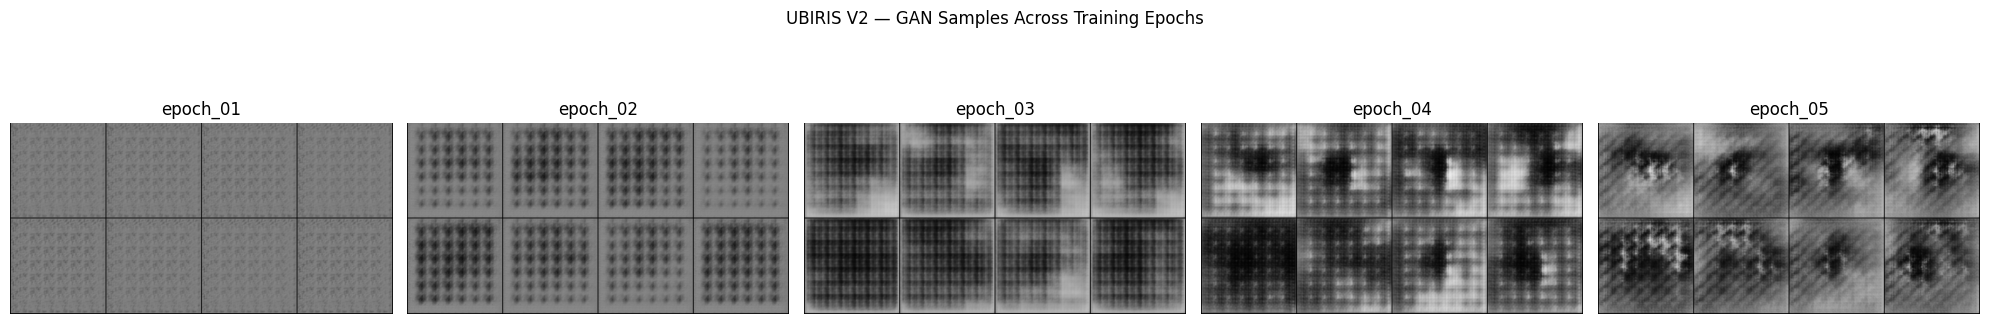

Preview files: 5
Comparison saved: /kaggle/working/ubiris_v2_project/notebook07_gan_augmentation/UBIRIS_V2_GAN_training_samples_comparison.png


In [27]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

OUT_DIR = Path("/kaggle/working/ubiris_v2_project/notebook07_gan_augmentation")
SAMPLE_DIR = OUT_DIR / "samples"
preview_files = sorted(SAMPLE_DIR.glob("UBIRIS_V2_GAN_epoch_*.png"))

assert len(preview_files) > 0, "No GAN sample previews found."

fig, axes = plt.subplots(1, len(preview_files), figsize=(4 * len(preview_files), 4))
if len(preview_files) == 1:
    axes = [axes]

for ax, path in zip(axes, preview_files):
    with Image.open(path) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(path.stem.replace("UBIRIS_V2_GAN_", ""))
    ax.axis("off")

fig.suptitle("UBIRIS V2 — GAN Samples Across Training Epochs")
fig.tight_layout()

FINAL_PREVIEW = OUT_DIR / "UBIRIS_V2_GAN_training_samples_comparison.png"
fig.savefig(FINAL_PREVIEW, dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Preview files:", len(preview_files))
print("Comparison saved:", FINAL_PREVIEW)


# Conclusion — GAN Augmentation on UBIRIS V2

A Deep Convolutional Generative Adversarial Network (DCGAN) was implemented to explore synthetic ocular image generation using the UBIRIS V2 dataset. The model was trained on 4,243 preprocessed grayscale training images resized to 224 × 224 pixels. The generator mapped 128-dimensional latent vectors to synthetic images, while the discriminator learned to distinguish real images from generated samples.

Training was conducted for five epochs using binary cross-entropy with logits and Adam optimizers. The learning rate was set to 0.0002, with Adam parameters β₁ = 0.5 and β₂ = 0.999. Model checkpoints, training-loss history, and sample previews were saved after each epoch.

The generator loss decreased from 4.48642 in epoch 1 to 2.14443 in epoch 5, although it fluctuated during training. The discriminator loss increased from 0.07038 in epoch 1 to 0.39968 in epoch 5. These changes describe the adversarial training dynamics but do not independently establish image quality or convergence.

Visual inspection of the generated samples showed evolving textures and intensity patterns across epochs. However, the outputs contained prominent repetitive grid-like patterns and artifacts and did not clearly resemble realistic ocular images in this preliminary experiment.

**Limitations:** Training was limited to five epochs, and no systematic hyperparameter search, quantitative image-quality evaluation, identity-preservation evaluation, or biometric recognition experiment was conducted at this stage. Consequently, the results do not establish that the generated images improve recognition performance or provide privacy guarantees.

**Conclusion:** The experiment established a functioning DCGAN training and sampling pipeline for UBIRIS V2, but the current configuration did not produce visibly convincing synthetic ocular images. The checkpoint, loss history, and epoch-wise previews are retained for reproducibility and comparison with the diffusion experiment and subsequent research stages.

In [28]:

from pathlib import Path
import zipfile
import pandas as pd
from IPython.display import display, FileLink

PROJECT = Path("/kaggle/working/ubiris_v2_project")
OUT_DIR = PROJECT / "notebook07_gan_augmentation"
ZIP_PATH = Path("/kaggle/working/UBIRIS_V2_Notebook07_Results.zip")

required = [
    OUT_DIR / "UBIRIS_V2_GAN_checkpoint.pth",
    OUT_DIR / "UBIRIS_V2_GAN_training_history.csv",
    OUT_DIR / "UBIRIS_V2_GAN_loss_curve.png",
    OUT_DIR / "UBIRIS_V2_GAN_training_samples_comparison.png",
]

for path in required:
    assert path.is_file(), f"Missing artifact: {path}"

history = pd.read_csv(required[1])
print("GAN TRAINING HISTORY")
print(history.to_string(index=False))

print("\nARTIFACT VERIFICATION")
for path in required:
    print(f"OK | {path.name} | {path.stat().st_size:,} bytes")

# Include checkpoint, history, plots, and all saved epoch previews.
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

file_count = 0
with zipfile.ZipFile(
    ZIP_PATH, "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=1,
    allowZip64=True
) as zf:
    for path in OUT_DIR.rglob("*"):
        if path.is_file():
            zf.write(path, path.relative_to(PROJECT))
            file_count += 1

print(f"\nFiles packaged: {file_count}")
print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")
print("ZIP saved:", ZIP_PATH)
display(FileLink(str(ZIP_PATH), result_html_prefix="Download Notebook 07 results: "))


GAN TRAINING HISTORY
 epoch  discriminator_loss  generator_loss  batches  epoch_seconds  learning_rate
     1            0.070384        4.486418      132          12.40         0.0002
     2            0.062652        6.395278      132          21.98         0.0002
     3            0.221214        3.719844      132          11.98         0.0002
     4            0.342680        2.758012      132          12.00         0.0002
     5            0.399675        2.144427      132          12.00         0.0002

ARTIFACT VERIFICATION
OK | UBIRIS_V2_GAN_checkpoint.pth | 37,113,173 bytes
OK | UBIRIS_V2_GAN_training_history.csv | 363 bytes
OK | UBIRIS_V2_GAN_loss_curve.png | 45,216 bytes
OK | UBIRIS_V2_GAN_training_samples_comparison.png | 597,483 bytes

Files packaged: 10
ZIP size: 34.95 MB
ZIP saved: /kaggle/working/UBIRIS_V2_Notebook07_Results.zip


/kaggle/working/UBIRIS_V2_Notebook07_Results.zip